<a href="https://colab.research.google.com/github/rlaj0730-design/Text-Mining/blob/main/ex01_%ED%85%8D%EC%8A%A4%ED%8A%B8_%EB%A7%88%EC%9D%B4%EB%8B%9D_%EA%B8%B0%EC%B4%88(%EB%82%98).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Text mining
- 비정형 데이터(ex : 텍스트) 에서 의미(인사이트)를 추출하는 작업
- 자연어 처리 기술도 접목해서 최근에 많이 수행이 되고 있는 추세
  - 자연어 처리 : 사람의 언어(텍스트, 음성 등)를 컴퓨터가 이해할 수 있도록 처리하는 일련의 과정
### 정형 데이터

| 이름 | 나이 | 성별 | 구매금액 |
|------|------|------|----------|
| 김민수 | 25 | 남 | 32,000원 |
| 이지은 | 31 | 여 | 15,000원 |
| 박서준 | 28 | 남 | 47,500원 |

→ 컴퓨터가 바로 계산 가능 (평균, 합계 등)

---

### 비정형 데이터

> "이 영화 진짜 노잼... 배우 연기는 좋았는데 스토리가 산으로 감"

→ 숫자로 딱 떨어지지 않는 텍스트 데이터. 사람은 바로 이해하지만, 컴퓨터는 그대로 계산할 수 없음

### Text mining의 영역

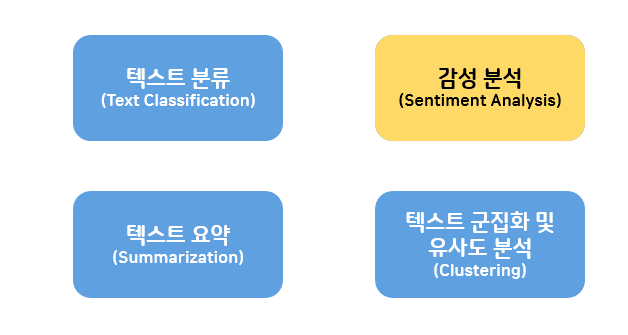

### Text mining Process
1. 텍스트 수집
2. 정제(전처리)
3. 토큰화
4. 수치화(컴퓨터가 이해할 수 있도록 변환)
5. 분석 및 적용


In [ ]:
# 구글 드라이브 마운트
# 코랩에서 구글 드라이브에 접근할 수 있도록 연결하는 작업이다.

# 마운트 작업이 필요한 이유
# 구글 드라이브에 저장된 파일을 코랩에서 불러오기 위해
# 코랩에서 작업한 결과를 구글 드라이브에 저장하기 위해

from google.colab import drive # 구글 드라이브를 사용하기 위한 모듈 불러오기
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 작업 디렉토리 변경(Change Directory)
%cd /content/drive/MyDrive/Colab Notebooks/동아 텍스트마이닝

/content/drive/MyDrive/Colab Notebooks/동아 텍스트마이닝


### 실습 목표
- 텍스트마이닝 프로세스를 직접 진행해보자.
- 영화 리뷰 데이터를 처리하여 감성분석(긍정/부정)을 진행해보자.

In [ ]:
# 필요한 라이브러리 import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 자동완성 : Ctrl+Space

In [ ]:
# 데이터 불러오기
text_train = pd.read_csv('./data/ratings_train.txt', delimiter='\t')
text_test = pd.read_csv('./data/ratings_test.txt', delimiter='\t')
# delimiter : 각 열이 탭(tab)으로 구분되어 있음

In [ ]:
# 데이터의 모양 확인
print(text_train.shape)
print(text_test.shape)


(150000, 3)
(50000, 3)


## 텍스트 전처리(Preprocessing)
- 전처리는 용도에 맞게 텍스트를 사전에 처리하는 작업
- 결측치 처리, 오탈자 제거, 띄어쓰기 교정

세부 작업

- **불용어 제거**: 데이터에서 큰 의미가 없는 단어 제거 (ex. 음, 뭐, 아 등)
- **정규화(normalization)**: 표현 방법이 다른 단어들을 통합하여 같은 단어로 만듦 (ex. 좋다, 지린다)
- **어간 추출(Stemming)**: 단어의 핵심 부분(어간)만 추출 (ex. 먹다, 먹고, 먹지, 먹어서 등)
- **표제어 추출(Lemmatization)**: 유사한 단어들에서 대표 단어를 추출 (am, are, is는 be동사)

In [ ]:
# 결측치 확인
# 데이터의 정보를 확인할 수 있는 함수
text_train.info()

# id : 리뷰를 작성한 사용자의 id
# document : 리뷰(문제 데이터, X)
# label : 리뷰의 긍/부정 여부 -> 0 : 부정, 1 : 긍정(정답데이터, y)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   id        150000 non-null  int64 
 1   document  149995 non-null  object
 2   label     150000 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 3.4+ MB


In [ ]:
text_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        50000 non-null  int64 
 1   document  49997 non-null  object
 2   label     50000 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.1+ MB


In [ ]:
text_train.isnull().sum()
# 결측치의 개수를 확인

,0
id,0
document,5
label,0


In [ ]:
text_test.isnull().sum()

,0
id,0
document,3
label,0


In [ ]:
from IPython.utils import text
# 결측치 처리
# 결측치를 다른 값으로 대체/결측치 제거
# 결측치 대체 : fillna()
# 결측치 제거 : dropna()

text_train.dropna(inplace=True)
text_test.dropna(inplace=True)
# inplace : True로 설정하면 원본데이터에 바로 적용된다.

In [ ]:
text_train.isnull().sum()

,0
id,0
document,0
label,0


In [ ]:
text_test.isnull().sum()

,0
id,0
document,0
label,0


### 토큰화, 수치화

- **토큰화(tokenization)**: 학습을 위해서 주어진 코퍼스(corpus, 말뭉치)에서 토큰(token)이라 불리는 단위로 나누는 작업 (공백기준, 형태소기준, 명사기준, 단어기준 등)
  - *말뭉치(corpus): 수집된 문서들의 집합*
  - 기준은 분석 방법에 따라 다름
  - 감성 분석을 한다면, 한글에서 감성을 나타내는 품사가 동사, 형용사 쪽에 가깝기 때문에 한글 형태소 분석기를 사용해서 동사, 형용사, (+명사) 위주로 추출

- **수치화(vectorization)**: 토큰화된 단어들을 컴퓨터가 계산할 수 있도록 숫자(벡터)로 변환하는 작업
  - **BOW(Bag of Words)**: 단어들의 순서를 전혀 고려하지 않고 단어들의 출현 빈도(frequency)에만 집중하는 텍스트 데이터의 수치화 표현 방법
    1. **CountVectorizer**: 단어의 출현 빈도를 단순 카운트하여 수치화
    2. **TF-IDF**: 단어의 출현 빈도(TF)와 함께, 여러 문서에 걸쳐 얼마나 희귀하게 등장하는지(IDF)를 함께 고려하여 가중치를 부여하는 수치화 방법

In [ ]:
# 단순 카운트 기반 수치화 도구 불러오기
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
# 수치화 도구 준비
cv = CountVectorizer()

In [ ]:
# 토큰화(띄어쓰기 단위로 분리) + 단어사전 구축
rv_train = text_train['document'] # 리뷰 텍스트만 추출
cv.fit(rv_train) # 리뷰들을 훑어보면서 단어사전 생성

CountVectorizer()

In [ ]:
# 단어사전 확인
cv.vocabulary_

# 단어 사전 : 단어 - 고유번호 쌍으로 구성

{'더빙': 71119,
 '진짜': 246232,
 '짜증나네요': 248358,
 '목소리': 99567,
 '포스터보고': 273335,
 '초딩영화줄': 255126,
 '오버연기조차': 190112,
 '가볍지': 16352,
 '않구나': 167602,
 '너무재밓었다그래서보는것을추천한다': 57394,
 '교도소': 33783,
 '이야기구먼': 208071,
 '솔직히': 145795,
 '재미는': 222295,
 '없다': 177352,
 '평점': 271982,
 '조정': 234711,
 '사이몬페그의': 133947,
 '익살스런': 210575,
 '연기가': 181881,
 '돋보였던': 74028,
 '영화': 185057,
 '스파이더맨에서': 150442,
 '늙어보이기만': 63331,
 '했던': 283593,
 '커스틴': 261359,
 '던스트가': 71680,
 '너무나도': 56734,
 '이뻐보였다': 207059,
 '걸음마': 25696,
 '3세부터': 5282,
 '초등학교': 254957,
 '1학년생인': 3039,
 '8살용영화': 7674,
 'ㅋㅋㅋ': 13347,
 '별반개도': 117898,
 '아까움': 160393,
 '원작의': 198609,
 '긴장감을': 43582,
 '제대로': 232430,
 '살려내지못했다': 134933,
 '반개도': 110754,
 '아깝다': 160496,
 '욕나온다': 194727,
 '이응경': 209070,
 '길용우': 43801,
 '연기생활이몇년인지': 182309,
 '정말': 230402,
 '발로해도': 112228,
 '그것보단': 36866,
 '낫겟다': 53960,
 '납치': 53930,
 '감금만반복반복': 18635,
 '이드라마는': 204973,
 '가족도없다': 17264,
 '연기못하는사람만모엿네': 182260,
 '액션이': 171312,
 '없는데도': 177305,
 '재미': 222156,
 '있는': 2148

In [ ]:
# 몇 개의 단어가 사전에 들어 갔는지 확인
len(cv.vocabulary_)

293366

In [ ]:
# 만들어진 단어사전을 기준으로 데이터 벡터화 진행
result = cv.transform(rv_train)

In [ ]:
print(result)
# 희소행렬로 반환
# 희소행렬은 0이 아닌 값의 위치와 값만 저장해서 메모리를 절약하는 자료구조

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1074805 stored elements and shape (149995, 293366)>
  Coords	Values
  (0, 71119)	1
  (0, 99567)	1
  (0, 246232)	1
  (0, 248358)	1
  (1, 16352)	1
  (1, 167602)	1
  (1, 190112)	1
  (1, 255126)	1
  (1, 273335)	1
  (2, 57394)	1
  (3, 33783)	1
  (3, 145795)	1
  (3, 177352)	1
  (3, 208071)	1
  (3, 222295)	1
  (3, 234711)	1
  (3, 271982)	1
  (4, 56734)	1
  (4, 63331)	1
  (4, 71680)	1
  (4, 74028)	1
  (4, 133947)	1
  (4, 150442)	1
  (4, 181881)	1
  (4, 185057)	1
  :	:
  (149990, 143710)	1
  (149990, 210829)	1
  (149991, 54243)	1
  (149991, 56643)	1
  (149991, 272521)	1
  (149992, 24486)	1
  (149992, 105397)	1
  (149992, 204171)	1
  (149992, 251014)	1
  (149992, 276532)	1
  (149992, 279753)	1
  (149992, 287413)	1
  (149993, 52347)	1
  (149993, 113562)	1
  (149993, 186872)	1
  (149993, 196356)	1
  (149993, 217551)	1
  (149993, 254425)	1
  (149993, 256303)	1
  (149994, 55879)	1
  (149994, 67785)	1
  (149994, 146244)	1
  (149994, 185057)	

In [ ]:
# 희소행렬을 numpy 배열로 변환
result.toarray()
# 행 : 리뷰 하나하나 / 열 : 전체 단어 사전의 단어들
# 각 칸의 값 : 해당 리뷰에 해당 단어가 몇 번 나왔는

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
result.toarray().shape
# 총 15만개의 행 -> 리뷰가 15만개
# 총 30만개의 열 -> 단어가 30만

(149995, 293366)

### 워드클라우드 시각화
- 텍스트 데이터 시각화 툴 -> 많이 등장하는 단어일수록 크게 출력
- 한눈에 대략적으로 텍스트 데이터의 내용을 파악할 수 있다는 장점.

In [ ]:
# 워드클라우드 설치
# !pip install wordcloud

In [ ]:
# 코랩에서 그래프의 한글 깨짐 현상을 방지하기 위한 글꼴 설치 및 설정
!apt-get install -y fonts-nanum* # 한글 글꼴 설치
!sudo fc-cache -fv # 시스템 글꼴 캐시 갱신
!rm ~/.cache/matplotlib -rf # matplotlib에 있는 기존 글꼴 정보를 새 글꼴로 설정

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'fonts-nanum-extra' for glob 'fonts-nanum*'
Note, selecting 'fonts-nanum-coding' for glob 'fonts-nanum*'
Note, selecting 'fonts-nanum-eco' for glob 'fonts-nanum*'
Note, selecting 'fonts-nanum' for glob 'fonts-nanum*'
The following NEW packages will be installed:
  fonts-nanum fonts-nanum-coding fonts-nanum-eco fonts-nanum-extra
0 upgraded, 4 newly installed, 0 to remove and 2 not upgraded.
Need to get 46.0 MB of archives.
After this operation, 177 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum-coding all 2.5-3 [4,988 B]
Get:3 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum-eco all 1.000-7 [14.7 MB]
Get:4 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum-extra all 20200506-1 [21.0 

In [ ]:
from wordcloud import WordCloud

In [ ]:
# 리뷰데이터를 하나로 합쳐서 워드클라우드용 텍스트 뭉치 생성하기
# temp = ""
# for doc in rv_train: # 리뷰를 하나씩 꺼내와서(doc)
#   temp += (" "+doc) # 띄어쓰기로 구분하며 temp에 이어붙힘

# temp

In [ ]:
# wc = WordCloud(
#     background_color = "white",
#     font_path ="/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
#     # 설치한 한글 글꼴의 경로(코랩 환경에서의 경로)
# )

In [ ]:
# cloud = wc.generate_from_text(temp)

In [ ]:
# # 원드클라우드 출력
# plt.imshow(cloud)
# plt.axis("off")
# plt.show()

### 텍스트 데이터의 구조

**말뭉치 >> 문서 >> 문단 >> 문장 >> 단어 >> 형태소**

- **말뭉치(corpus)**: 분석을 위해 수집된 문서들의 집합
- 말뭉치는 여러 개의 **문서**로 구성
- **문서**는 여러 개의 **문단**으로 구성
- **문단**은 여러 개의 **문장**으로 구성
- **문장**은 여러 개의 **단어**로 구성
- **단어**는 여러 개의 **형태소**로 구성
  - *형태소: 일정한 의미가 있는 가장 작은 말의 단위*


### 형태소 분석기

- **형태소**: 일정한 의미가 있는 가장 작은 말의 단위
  - ex) 먹었습니다 → 먹(다) + 었(과거) + 습니다(높임, 문장끝)
- 한글은 조사(은/는/이/가)나 어미(다/요/습니다)가 단어에 붙어있어서, 단순 띄어쓰기 기준으로 토큰화하면 '좋다', '좋아요', '좋았어요'가 전부 다른 단어로 취급됨
  - → 형태소 분석기를 사용하면 이런 표현들을 정확하게 쪼개고 정리 가능

**형태소 분석기 패키지**

- **konlpy**: 한국어 자연어 처리(KOrean NLP)를 위한 파이썬 도구 모음
  - 여러 형태소 분석기 포함 (Okt, Kkma 등)
- **kiwipiepy**: 'Kiwi'라는 한국어 형태소 분석기를 파이썬에서 사용할 수 있게 해주는 패키지
  - konlpy에 속하지 않은 별도 분석기
  - 띄어쓰기 교정 기능, 빠른 처리 속도가 특징

In [ ]:
# 형태소 분석기 설치
!pip install konlpy
!pip install kiwipiepy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.5/438.5 kB 29.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 12.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 106.4 MB/s eta 0:00:00
  Created wheel for kiwipiepy_model: filename=kiwipiepy_model-0.24.0-py3-none-any.whl size=87973829 sha256=a1589bceade632e3e13f1cd658c7a49e8a462eb3ed74f57710335ff26f07ab6b
  Stored in directory: /root/.cache/pip/wheels/1e/08/d4/4ff00b71c6b738e5308a0867385c986a743e5307c5206da985
Successfully built kiwipiepy_model


In [ ]:
# konlpy가 제공하는 형태소 분석기 중
# okt, kkma 불러오기
from konlpy.tag import Okt, Kkma

In [ ]:
# 형태소 분석기 객체 생성
okt = Okt()
kkma = Kkma()

### Okt형태소 분석기

In [ ]:
# 형태소 분리
okt.morphs("아버지가 방에 들어가신다.")

['아버지', '가', '방', '에', '들어가신다', '.']

In [ ]:
# 형태소 분리 후 품사 붙여주기
okt.pos("아버지가 방에 들어가신다.")

[('아버지', 'Noun'),
 ('가', 'Josa'),
 ('방', 'Noun'),
 ('에', 'Josa'),
 ('들어가신다', 'Verb'),
 ('.', 'Punctuation')]

In [ ]:
okt.tagset

{'Adjective': '형용사',
 'Adverb': '부사',
 'Alpha': '알파벳',
 'Conjunction': '접속사',
 'Determiner': '관형사',
 'Eomi': '어미',
 'Exclamation': '감탄사',
 'Foreign': '외국어, 한자 및 기타기호',
 'Hashtag': '트위터 해쉬태그',
 'Josa': '조사',
 'KoreanParticle': '(ex: ㅋㅋ)',
 'Noun': '명사',
 'Number': '숫자',
 'PreEomi': '선어말어미',
 'Punctuation': '구두점',
 'ScreenName': '트위터 아이디',
 'Suffix': '접미사',
 'Unknown': '미등록어',
 'Verb': '동사'}

kkma(꼬꼬마) 형태소 분석기

In [ ]:
# 형태소 분리
kkma.morphs("아버지가 방에 들어가신다.")

['아버지', '가', '방', '에', '들어가', '시', 'ㄴ다', '.']

In [ ]:
kkma.pos("아버지가 방에 들어가신다.")

[('아버지', 'NNG'),
 ('가', 'JKS'),
 ('방', 'NNG'),
 ('에', 'JKM'),
 ('들어가', 'VV'),
 ('시', 'EPH'),
 ('ㄴ다', 'EFN'),
 ('.', 'SF')]

In [ ]:
kkma.tagset

{'EC': '연결 어미',
 'ECD': '의존적 연결 어미',
 'ECE': '대등 연결 어미',
 'ECS': '보조적 연결 어미',
 'EF': '종결 어미',
 'EFA': '청유형 종결 어미',
 'EFI': '감탄형 종결 어미',
 'EFN': '평서형 종결 어미',
 'EFO': '명령형 종결 어미',
 'EFQ': '의문형 종결 어미',
 'EFR': '존칭형 종결 어미',
 'EP': '선어말 어미',
 'EPH': '존칭 선어말 어미',
 'EPP': '공손 선어말 어미',
 'EPT': '시제 선어말 어미',
 'ET': '전성 어미',
 'ETD': '관형형 전성 어미',
 'ETN': '명사형 전성 어미',
 'IC': '감탄사',
 'JC': '접속 조사',
 'JK': '조사',
 'JKC': '보격 조사',
 'JKG': '관형격 조사',
 'JKI': '호격 조사',
 'JKM': '부사격 조사',
 'JKO': '목적격 조사',
 'JKQ': '인용격 조사',
 'JKS': '주격 조사',
 'JX': '보조사',
 'MA': '부사',
 'MAC': '접속 부사',
 'MAG': '일반 부사',
 'MD': '관형사',
 'MDN': '수 관형사',
 'MDT': '일반 관형사',
 'NN': '명사',
 'NNB': '일반 의존 명사',
 'NNG': '보통명사',
 'NNM': '단위 의존 명사',
 'NNP': '고유명사',
 'NP': '대명사',
 'NR': '수사',
 'OH': '한자',
 'OL': '외국어',
 'ON': '숫자',
 'SE': '줄임표',
 'SF': '마침표, 물음표, 느낌표',
 'SO': '붙임표(물결,숨김,빠짐)',
 'SP': '쉼표,가운뎃점,콜론,빗금',
 'SS': '따옴표,괄호표,줄표',
 'SW': '기타기호 (논리수학기호,화폐기호)',
 'UN': '명사추정범주',
 'VA': '형용사',
 'VC': '지정사',
 'VCN': "부정 지정사, 형용사 '아니다'",
 'VC

### 키위 형태소 분석기

In [ ]:
from kiwipiepy import Kiwi

In [ ]:
kiwi = Kiwi()

In [ ]:
# 띄어쓰기 교정 기능 확인
kiwi.space("띄어쓰기없이작성된텍스트입니다.키위형태소분석기의성능을확인해보겠습니다")

'띄어쓰기 없이 작성된 텍스트입니다. 키위 형태소 분석기의 성능을 확인해 보겠습니다'

In [ ]:
kiwi.tokenize("아버지가 방에 들어가신다.")
# form : 원형
# tag : 품사
# start : 시작 인덱스
# len : 형태소 길이

[Token(form='아버지', tag='NNG', start=0, len=3),
 Token(form='가', tag='JKS', start=3, len=1),
 Token(form='방', tag='NNG', start=5, len=1),
 Token(form='에', tag='JKB', start=6, len=1),
 Token(form='들어가', tag='VV', start=8, len=3),
 Token(form='시', tag='EP', start=11, len=1),
 Token(form='ᆫ다', tag='EF', start=11, len=2),
 Token(form='.', tag='SF', start=13, len=1)]

In [ ]:
# 품사 분류 확인하기
# - https://bab2min.github.io/kiwipiepy/
# - '태그 목록' 검색

## 한국어 형태소 분석기 비교
- https://konlpy.org/ko/v0.6.0/morph/

| **토큰화 도구** | **설명** | **장점** | **단점** | **사용하면 좋은 글 유형** |
|----------------|---------|---------|---------|------------------|
| **KoNLPy - Okt** | 트위터에서 개발한 한국어 형태소 분석기 | - 속도가 빠름 <br> - 줄임말, 신조어에 강함 <br> - 명사, 동사, 형용사 태깅 지원 | - 분석 정확도가 상대적으로 낮음 <br> - 긴 문장에서 오탈자나 오류 발생 가능 | - SNS 댓글, 트위터, 카톡 대화 등 구어체 데이터 |
| **KoNLPy - Mecab** | 일본 Mecab을 한국어에 맞게 수정한 형태소 분석기 | - 속도가 가장 빠름 <br> - 비교적 높은 정확도 <br> - 메모리 사용량 적음 | - 윈도우 환경에서 설치가 까다로움 <br> - 사용자 사전 추가 필요 | - 뉴스, 문서 요약, 법률 문서 등 정형 데이터 |
| **KoNLPy - Kkma** | 서울대에서 개발한 형태소 분석기 | - 구문 분석 기능 포함 <br> - 문장 분리 기능 제공 | - 속도가 느림 <br> - 명사 추출 시 과도한 분할 발생 가능 | - 학술 논문, 문서 분석, 보고서 |
| **KoNLPy - Komoran** | Shineware에서 개발한 형태소 분석기 | - 딥러닝 기반으로 정확도 높음 <br> - 사용자 사전 확장 가능 | - 속도가 느린 편 | - 뉴스 기사, 공식 문서, 챗봇 |
| **KoNLPy - Hannanum** | KAIST에서 개발한 한국어 형태소 분석기 | - 어절 분석 및 띄어쓰기 보정 기능 제공 <br> - 구문 분석 가능 | - 속도가 느림 <br> - 비교적 오래된 기술로 최신 트렌드 반영 부족 | - 논문, 신문 기사, 공식 문서 |
| **Kiwi** | 한국어 형태소 분석기 (KyTea의 통계적 기법 기반) | - 최신 기술 적용 <br> - 속도와 정확도 균형 잡힘 <br> - 신조어, 띄어쓰기 보정 기능 제공 | - 비교적 새로운 도구라 참고 자료 부족 | - 검색 엔진, 챗봇, 감성 분석 |


In [ ]:
# 유의미한 형태소들만 골라내기
# 불용어 제거 + 품사 필터링
# kiwipiepy에 내장된 불용어(stopword) 목록 불러오기
from kiwipiepy.utils import Stopwords

In [ ]:
# 객체 생성
stopwords = Stopwords()

In [ ]:
# 불용어 리스트 확인하기
stopwords.stopwords

{('ᆫ', 'ETM'),
 ('ᆫ', 'JX'),
 ('ᆫ다', 'EF'),
 ('ᆯ', 'ETM'),
 ('가', 'JKS'),
 ('같', 'VA'),
 ('것', 'NNB'),
 ('게', 'EC'),
 ('겠', 'EP'),
 ('고', 'EC'),
 ('고', 'JKQ'),
 ('과', 'JC'),
 ('과', 'JKB'),
 ('그', 'MM'),
 ('그', 'NP'),
 ('기', 'ETN'),
 ('까지', 'JX'),
 ('나', 'NP'),
 ('년', 'NNB'),
 ('는', 'ETM'),
 ('는', 'JX'),
 ('다', 'EC'),
 ('다', 'EF'),
 ('다고', 'EC'),
 ('다는', 'ETM'),
 ('대하', 'VV'),
 ('더', 'MAG'),
 ('던', 'ETM'),
 ('도', 'JX'),
 ('되', 'VV'),
 ('되', 'XSV'),
 ('들', 'XSN'),
 ('등', 'NNB'),
 ('따르', 'VV'),
 ('때', 'NNG'),
 ('때문', 'NNB'),
 ('라', 'EC'),
 ('라는', 'ETM'),
 ('로', 'JKB'),
 ('를', 'JKO'),
 ('만', 'JX'),
 ('만', 'NR'),
 ('말', 'NNG'),
 ('며', 'EC'),
 ('면', 'EC'),
 ('면서', 'EC'),
 ('명', 'NNB'),
 ('받', 'VV'),
 ('보', 'VV'),
 ('부터', 'JX'),
 ('사람', 'NNG'),
 ('성', 'XSN'),
 ('수', 'NNB'),
 ('아니', 'VCN'),
 ('않', 'VX'),
 ('어', 'EC'),
 ('어', 'EF'),
 ('어서', 'EC'),
 ('어야', 'EC'),
 ('없', 'VA'),
 ('었', 'EP'),
 ('에', 'JKB'),
 ('에게', 'JKB'),
 ('에서', 'JKB'),
 ('와', 'JC'),
 ('와', 'JKB'),
 ('우리', 'NP'),
 ('원', 'NNB'),


In [ ]:
total = [] # 유의미한 형태소들만 담기
from tqdm import tqdm # 반복문 진행현황을 bar 형태로 시각화 해주는 툴

for doc in tqdm(rv_train) :
  # 불용어 리스트를 반영해서 불용어 제거
  result = kiwi.tokenize(doc, stopwords = stopwords)
  temp = [] # 행별(리뷰별)로 유의미한 형태소를 담을 리스트
  # 필요한 품사만 필터링
  for token in result :
    if token.tag in ["NNG", "VV", "VA"] : # 일반명사, 동사, 형용사만을 필터링
      temp.append(token.form) # 형태소의 문자열만 temp에 담아줌
  total.append(temp)

100%|██████████| 149995/149995 [02:59<00:00, 836.36it/s] 


In [ ]:
total

[['더빙', '짜증', '나', '목소리'],
 ['포스터', '초딩', '영화', '줄', '오버', '연기'],
 ['밓', '추천'],
 ['교도소', '이야기', '재미', '평점', '조정'],
 ['익살', '연기', '돋보이', '영화', '늙', '보이', '이쁘', '보이'],
 ['걸음마', '떼', '초등학교', '학년', '영화', '반'],
 ['원작', '긴장감', '살리'],
 ['별',
  '반',
  '욕',
  '나오',
  '연기',
  '생활',
  '발',
  '납치',
  '감금',
  '반복',
  '반복',
  '드라마',
  '가족',
  '연기',
  '모이'],
 ['액션', '재미', '영화'],
 ['평점', '낮', '길들이'],
 ['짱', '짱'],
 ['눈물', '나', '죽', '향수', '자극', '감성', '절제', '멜로', '달인'],
 ['울', '손', '들', '횡단보도', '건너', '뛰쳐나오', '연기'],
 ['좋', '신문', '기사', '잊어버리'],
 ['취향',
  '존중',
  '진짜',
  '생',
  '극장',
  '영화',
  '노',
  '잼',
  '노',
  '감동',
  '스토리',
  '어거지',
  '감동',
  '어거지'],
 ['긴장', '재밋'],
 ['웃기', '바스코가', '이기', '이기', '깔', '까', '안달', '나', '보이'],
 ['표절', '이해', '뒤', '가', '재미'],
 ['깨알', '캐스팅', '내용', '구성', '버무러진', '깨알일드'],
 ['약탈자', '변명', '착하'],
 ['뜻', '학생', '선생', '놀아나', '영화'],
 ['가능'],
 ['재미없',
  '음식',
  '영화',
  '차이',
  '나',
  '이야기',
  '음식',
  '재미',
  '음식',
  '나오',
  '풍경',
  '구경',
  '나오'],
 ['영화', '수작', '말씀', '드리'],
 ['주제', '좋', '중

In [ ]:
# okt로도 동일하게 진행
total_okt = []

for doc in tqdm(rv_train) :
  result = okt.pos(doc, stem=True) # stem = True : 단어를 기본형으로 바꿔서 추출
  temp = []
  for word, tag in result :
    if tag in ["Noun", "Verb", "Adjective"] : # 명사, 동사, 형용사만 추출
      temp.append(word)
  total_okt.append(temp)

100%|██████████| 149995/149995 [10:38<00:00, 235.05it/s]


In [ ]:
# 워드클라우드를 그려서 비교해보자

# kiwi 형태소 분석 결과를 2차원 -> 1차원
kiwi_tokens = []
for i in total :
  kiwi_tokens += i
kiwi_str = " ".join(kiwi_tokens) #띄어쓰기로 구분된 하나의 문자열이 만들어짐

In [ ]:
# okt 형태소 분석 결과를 2차원 -> 1차원
okt_tokens = []
for i in total_okt :
  okt_tokens += i
okt_str = " ".join(okt_tokens)

In [ ]:
kiwi_str

'더빙 짜증 나 목소리 포스터 초딩 영화 줄 오버 연기 밓 추천 교도소 이야기 재미 평점 조정 익살 연기 돋보이 영화 늙 보이 이쁘 보이 걸음마 떼 초등학교 학년 영화 반 원작 긴장감 살리 별 반 욕 나오 연기 생활 발 납치 감금 반복 반복 드라마 가족 연기 모이 액션 재미 영화 평점 낮 길들이 짱 짱 눈물 나 죽 향수 자극 감성 절제 멜로 달인 울 손 들 횡단보도 건너 뛰쳐나오 연기 좋 신문 기사 잊어버리 취향 존중 진짜 생 극장 영화 노 잼 노 감동 스토리 어거지 감동 어거지 긴장 재밋 웃기 바스코가 이기 이기 깔 까 안달 나 보이 표절 이해 뒤 가 재미 깨알 캐스팅 내용 구성 버무러진 깨알일드 약탈자 변명 착하 뜻 학생 선생 놀아나 영화 가능 재미없 음식 영화 차이 나 이야기 음식 재미 음식 나오 풍경 구경 나오 영화 수작 말씀 드리 주제 좋 중반 짜르 납득 고추 털 발 연기 재밋 센스 연출력 캐스팅 향수 엄포스 위력 남 꽃 검사 연기 좋 명품 드라마 졸 쓰레기 시간 재밌 별점 낮 기대 죄인 죄인 드라마 인생 최고 패션 열정 연기 정신 장애 틱 장애 작가 재미있 포스터 있 보이 관객 영화 평가 모르 단순 매력 영화 알바 내용 웃기 영화 넘 낚이 오 서리 한 굶주리 맘 들 방법 멋지 배우 발견 소소하 일탈 미소 머금 음악 주 평점 올리 주 평점 속 시간 낭비 돈 낭비 리얼리티 뛰어나 크 공감 가 캐릭터 정신 의학 분노 조절 장애 초기 증상 패 욕하 물건 파손 오바 극 초반 가 가 정신 상태 공감 불가 마이너스 뮤비 영화 수준 알 만들 돈 대 영화 사랑 데너리스 타르 가르엔 용 주인 누이 근친상간 다니 소설 속 멋지 메 라니스터 드라마 속 드래곤 용 멋지 웃음 감독 월드 말 잡수 기본 선 방 영화 영혼 어루만지 있 거칠 세상사 잊 동화 영화 행복 작 고추 맛 보이 포퐁저그 콩진호 가 가슴 시리 드라마 감동 자체 꼬마 애 원한 깊 나대 어쩌 재미있 좋 최고 충격 기분 꺼지 느낌 활력 자비 일본인 상상력 대단하 생각 들 영화 나오 들어맞 예측 카리스마 악역 불알

In [ ]:
# kiwi로 형태소 분석한 문자열 wordcloud 그리기
kiwi_cloud = WordCloud(
     background_color = "white",
     font_path ="/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
    ).generate_from_text(kiwi_str)

In [ ]:
# okt로 형태소 분석한 문자열 wordcloud 그리기
okt_cloud = WordCloud(
     background_color = "white",
     font_path ="/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
    ).generate_from_text(okt_str)

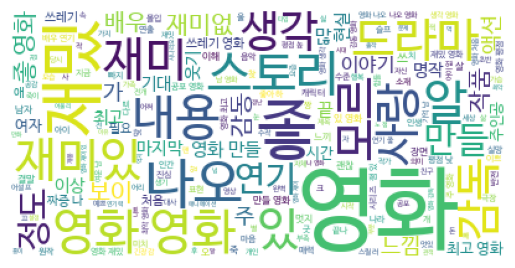

In [ ]:
plt.imshow(kiwi_cloud)
plt.axis("off")
plt.show()

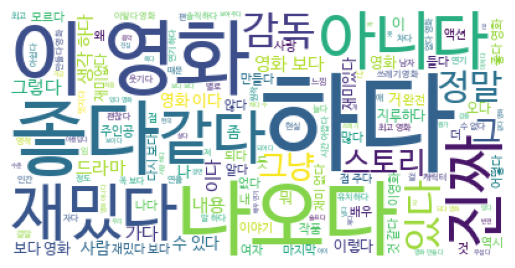

In [ ]:
plt.imshow(okt_cloud)
plt.axis("off")
plt.show()

### 모델링
- 텍스트 데이터 -> 벡터화 -> 긍정/부정(이진분류)


In [ ]:
# 단순 카운트 기반 벡터화 도구
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
cv = CountVectorizer()

In [ ]:
# 단어 사전 구축
cv.fit(rv_train)

CountVectorizer()

In [ ]:
# 만들어진 단어사전을 기준으로 벡터화
X_train = cv.transform(text_train["document"])
X_test = cv.transform(text_test["document"])
# 학습 데이터로 만든 단어사전을 기준으로 테스트 데이터의 단어별 등장 빈도를 계산해서 벡터화

In [ ]:
len(cv.vocabulary_), X_train.shape, X_test.shape

(293366, (149995, 293366), (49997, 293366))

In [ ]:
# 정답 데이터
y_train = text_train["label"]
y_test = text_test["label"]

In [ ]:
# 우리는 '리뷰가 긍정이냐 부정이냐' 둘 중 하나를 고르는 이진 분류 문제
# 로지스틱 회귀 : 이진 분류에 특화된 모델

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [ ]:
# 모델 객체 생성
logi_model = LogisticRegression(max_iter = 1000)
# max_iter : 모델이 가중치를 수정하는 과정을 반복할 수 있는 최대 횟수 (기본값 100)
# 기본값 100은 데이터가 많아지면 제대로 학습이 안 될 수 있음
# 가중치 수정 반복 횟수를 늘려 모델이 가중치를 수정할 기회를 더 주기 위함

In [ ]:
# 모델 학습
logi_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
result = cross_val_score(logi_model, X_train, y_train, cv=5)
# 학습 데이터를 5개의 블록으로 나누어 교차검증을 진행

In [ ]:
print(result.mean(), result)
# 결과 해석
# 평균 정확도는 약 81%
# 검증 데이터의 리뷰 100개 중 약 81개를 올바르게 긍정/부정으로 분류했다는 의미

0.8120137337911263 [0.81332711 0.81222707 0.8089603  0.80932698 0.81622721]


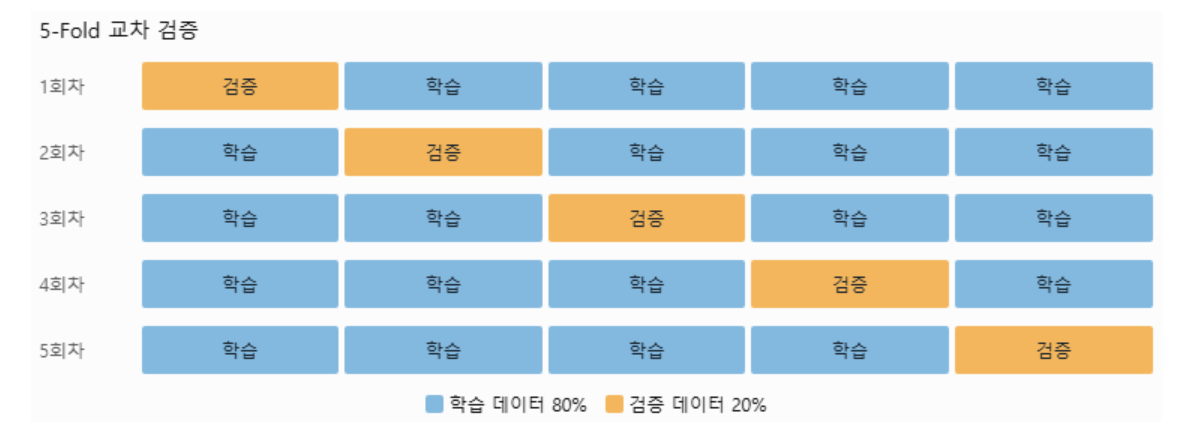

In [ ]:
# 테스트 데이터를 활용한 모델 성능 평가
test_score = logi_model.score(X_test, y_test)

In [ ]:
test_score

0.814868892133528

In [ ]:
# 예측 성능을 새로운 데이터를 통해서 확인
test = [
    "시간 가는 줄 모르고 재미있게 봤어요",
    "아 괜히 봤음. 돈 아까움!",
    "또 보고싶을 정도로 감동적이었음"
]

In [ ]:
# 테스트 데이터도 모델에 넘겨주기 전에 벡터화를 진행해야 함
sample = cv.transform(test)

In [ ]:
pred = logi_model.predict(sample)
pred

array([1, 0, 1])

토큰화 내용 반영해서 모델링 다시 진행

In [ ]:
total = [] # 유의미한 형태소들만 담기
from tqdm import tqdm # 반복문 진행현황 bar 형태로 시각화 툴

for doc in tqdm(rv_train) :
  # 불용어 리스트를 반영해서 불용어 제거
  result = kiwi.tokenize(doc, stopwords = stopwords)
  temp = [] # 행별(리뷰별)로 유의미한 형태소를 담을 리스트
  # 필요한 품사만 필터링
  for token in result :
    if token.tag in ["NNG", "VV", "VA"] : # 일반명사, 동사, 형용사만을 필터링
      temp.append(token.form) # 형태소의 문자열만 temp에 담아줌
  total.append(temp)

100%|██████████| 149995/149995 [02:33<00:00, 980.34it/s]


In [ ]:
total

[['더빙', '짜증', '나', '목소리'],
 ['포스터', '초딩', '영화', '줄', '오버', '연기'],
 ['밓', '추천'],
 ['교도소', '이야기', '재미', '평점', '조정'],
 ['익살', '연기', '돋보이', '영화', '늙', '보이', '이쁘', '보이'],
 ['걸음마', '떼', '초등학교', '학년', '영화', '반'],
 ['원작', '긴장감', '살리'],
 ['별',
  '반',
  '욕',
  '나오',
  '연기',
  '생활',
  '발',
  '납치',
  '감금',
  '반복',
  '반복',
  '드라마',
  '가족',
  '연기',
  '모이'],
 ['액션', '재미', '영화'],
 ['평점', '낮', '길들이'],
 ['짱', '짱'],
 ['눈물', '나', '죽', '향수', '자극', '감성', '절제', '멜로', '달인'],
 ['울', '손', '들', '횡단보도', '건너', '뛰쳐나오', '연기'],
 ['좋', '신문', '기사', '잊어버리'],
 ['취향',
  '존중',
  '진짜',
  '생',
  '극장',
  '영화',
  '노',
  '잼',
  '노',
  '감동',
  '스토리',
  '어거지',
  '감동',
  '어거지'],
 ['긴장', '재밋'],
 ['웃기', '바스코가', '이기', '이기', '깔', '까', '안달', '나', '보이'],
 ['표절', '이해', '뒤', '가', '재미'],
 ['깨알', '캐스팅', '내용', '구성', '버무러진', '깨알일드'],
 ['약탈자', '변명', '착하'],
 ['뜻', '학생', '선생', '놀아나', '영화'],
 ['가능'],
 ['재미없',
  '음식',
  '영화',
  '차이',
  '나',
  '이야기',
  '음식',
  '재미',
  '음식',
  '나오',
  '풍경',
  '구경',
  '나오'],
 ['영화', '수작', '말씀', '드리'],
 ['주제', '좋', '중

In [ ]:
len(total)

149995

In [ ]:
# 행별로 하나의 문장으로 합쳐줘야 벡터화를 진행할 수 있음
docs_joined = []
for tokens in total :
  docs_joined.append(" ".join(tokens)) # 리뷰 안의 단어들을 띄어쓰기로 합쳐서 문자열로 만들고 저장

docs_joined

['더빙 짜증 나 목소리',
 '포스터 초딩 영화 줄 오버 연기',
 '밓 추천',
 '교도소 이야기 재미 평점 조정',
 '익살 연기 돋보이 영화 늙 보이 이쁘 보이',
 '걸음마 떼 초등학교 학년 영화 반',
 '원작 긴장감 살리',
 '별 반 욕 나오 연기 생활 발 납치 감금 반복 반복 드라마 가족 연기 모이',
 '액션 재미 영화',
 '평점 낮 길들이',
 '짱 짱',
 '눈물 나 죽 향수 자극 감성 절제 멜로 달인',
 '울 손 들 횡단보도 건너 뛰쳐나오 연기',
 '좋 신문 기사 잊어버리',
 '취향 존중 진짜 생 극장 영화 노 잼 노 감동 스토리 어거지 감동 어거지',
 '긴장 재밋',
 '웃기 바스코가 이기 이기 깔 까 안달 나 보이',
 '표절 이해 뒤 가 재미',
 '깨알 캐스팅 내용 구성 버무러진 깨알일드',
 '약탈자 변명 착하',
 '뜻 학생 선생 놀아나 영화',
 '가능',
 '재미없 음식 영화 차이 나 이야기 음식 재미 음식 나오 풍경 구경 나오',
 '영화 수작 말씀 드리',
 '주제 좋 중반',
 '짜르 납득',
 '고추 털',
 '발 연기',
 '재밋',
 '센스 연출력 캐스팅 향수',
 '엄포스 위력 남 꽃 검사 연기 좋 명품 드라마',
 '졸 쓰레기 시간',
 '재밌 별점 낮',
 '기대 죄인 죄인',
 '드라마 인생 최고',
 '패션 열정',
 '연기 정신 장애 틱 장애',
 '작가 재미있',
 '포스터 있 보이 관객',
 '영화 평가 모르',
 '단순 매력 영화',
 '알바 내용 웃기 영화 넘 낚이',
 '오 서리 한 굶주리',
 '맘 들 방법',
 '멋지 배우 발견 소소하 일탈 미소 머금 음악 주 평점 올리 주',
 '평점 속 시간 낭비 돈 낭비',
 '리얼리티 뛰어나 크 공감 가 캐릭터 정신 의학 분노 조절 장애 초기 증상 패 욕하 물건 파손 오바 극 초반 가 가 정신 상태 공감 불가',
 '마이너스 뮤비 영화 수준 알 만들 돈 대',
 '영화 사랑',
 '데너리스 타르 가르엔 용 주인 누이 근친상간 다니 소설 속 

In [ ]:
len(docs_joined)

149995

In [ ]:
# 단어사전 만들기
tk_cv = CountVectorizer()
tk_cv.fit(docs_joined)

CountVectorizer()

In [ ]:
# 벡터화
X_train_tk = tk_cv.transform(docs_joined)

In [ ]:
X_train_tk.shape, y_train.shape

((149995, 26233), (149995,))

In [ ]:
# 모델링
logi_model2 = LogisticRegression(max_iter = 1000)
logi_model2.fit(X_train_tk, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
X_train_tk.shape, y_train.shape

((149995, 26233), (149995,))

In [ ]:
# 교차검증 결과 확인
result_tk = cross_val_score(logi_model2, X_train_tk, y_train, cv = 5)
print(result_tk.mean(), result_tk)

0.758905296843228 [0.75855862 0.76045868 0.75825861 0.75889196 0.75835861]


### 토큰화된 데이터를 사용해서 모델링을 하는게 리뷰데이터를 가지고 분석하는 상황에 적절하지 않을 수 있음

- 실제로 교차검증 정확도를 비교해보면, 형태소 분석을 적용하기 전(0.812)보다
  적용한 후(0.759)의 성능이 더 낮아짐

- 원인
  1. 품사 필터링(NNG, VV, VA)에서 걸러지는 표현들
     - ㅋㅋㅋ, ㅎㅎ, ㅡㅡ 같은 표현은 명사/동사/형용사가 아니라서 필터에서 제외됨
     - 하지만 리뷰(구어체, 인터넷 말투)에서는 이런 표현이 감정의 강도나 뉘앙스를
       나타내는 중요한 신호인 경우가 많음
      - ex) "이걸 영화라고 만들었냐ㅋㅋㅋㅋㅋ" → 여기서 'ㅋㅋㅋㅋㅋ'는 웃긴 게 아니라
    "어이가 없어서 헛웃음이 난다"는 비웃음, 부정적 뉘앙스를 담고 있음
    → 품사 필터링을 거치면 'ㅋㅋㅋㅋㅋ'가 통째로 사라지고 "영화", "만들다" 정도만
    남아서, 이 문장의 진짜 감정(비웃음, 실망)이 거의 안 드러나게 됨

  2. 정규화(norm), 원형 추출(stem) 과정에서 발생하는 정보 손실
     - 비표준 표현들을 표준어로 통일하고 원형으로 복원하는 과정에서,
       원문이 가진 강조나 뉘앙스가 사라질 수 있음

  3. 반대로 단순 CountVectorizer(형태소 분석 X)는 "먹었닼ㅋㅋㅋ" 같은 표현을
     그대로 하나의 토큰으로 유지 → 이런 특이한 표현 자체가 특정 감성과
     강하게 연결된 신호로 학습에 활용됨

- 결론: '더 정제된 데이터 = 더 좋은 성능'이 항상 성립하는 건 아니며,
  데이터의 특성(리뷰의 구어체·이모티콘·강조 표현 등)에 따라
  전처리 방식을 신중하게 선택해야 함